В цьому домашньому завданні відпрацюємо з вами знання, отримані в модулі зі статистики.

**Завдання 1.** Ми обговорили з Вами на лекції, що велика літера Сігма грецького алфавіту позначає в математиці суму. Знайдіть з використанням Python $\Sigma x$, $\Sigma x^2$, та $\Sigma (x-1)^2$ для наступного набору даних:
`1 3 4`
Виведіть результат кожного обчислення на екран.

In [81]:
import numpy as np
import matplotlib.pyplot as plt

In [82]:
data = [1, 3, 4]

print("Σx:", sum(data))
print("Σx^2:", sum(x**2 for x in data))
print("Σ(x−1)^2:", sum((x - 1)**2 for x in data))

Σx: 8
Σx^2: 26
Σ(x−1)^2: 13


**Завдання 2.** Ми зібрали дані про суму покупок в гривнях 20ма випадково обраними клієнтами в нашому магазині (всього клієнтів у нас більше) за минулий місяць. Вони представлені в змінній `sum_purchases`. Знайдіть **вибіркове середнє** для цих даних кожним з зазначених методів:   

  2.1. без використання жодних бібліотек, користуючись тільки Python.  
  2.2. використовуючи відповідний метод бібліотеки `numpy`.

  Виведіть результат обчислень в кожному з випадків на екран та порівняйте результати. Вони співпадають?

In [83]:
sum_purchases = [ 316,  493,  367,  153,  224,  121,  322,  450,  196,  397,  281,
  239,  484,  124,  223,  448,  432,  255, 4310, 3524]

In [84]:
# 2.1 тільки Python
mean_python = sum(sum_purchases) / len(sum_purchases)
print("Середнє (Python):", mean_python)

# 2.2 numpy
import numpy as np
mean_numpy = np.mean(sum_purchases)
print("Середнє (NumPy):", mean_numpy)

# Порівняння
print("Результати співпадають:", mean_python == mean_numpy)

Середнє (Python): 667.95
Середнє (NumPy): 667.95
Результати співпадають: True


**Завдання 3.** Для того ж набору даних в змінній `sum_purchases` обчисліть **медіану** кожним з зазначених методів:  

  3.1. без використання жодних бібліотек, користуючись тільки Python.  
  3.2. використовуючи відповідний метод бібліотеки numpy.  

Виведіть результат обчислень в кожному з випадків на екран. Порівняйте результати зі значенням вибіркового середнього. Напишіть коментар, для яких задач ви б використовували вибіркове середнє, а для яких - медіану?

In [85]:
# 3.1 тільки Python
def median(data):
    sorted_data = sorted(data)
    items_count = len(sorted_data)
    center_index = (items_count - 1) // 2
    items_count_is_even = items_count % 2 == 0

    if items_count_is_even:
        # парна кількість: середнє двох центральних
        return (sorted_data[center_index] + sorted_data[center_index + 1]) / 2.0
    else:
        # непарна кількість: беремо середній елемент
        return sorted_data[center_index]


median_python = median(sum_purchases)
print("Медіана (Python):", median_python)

# 3.2 numpy
median_numpy = np.median(sum_purchases)
print("Медіана (NumPy):", median_numpy)

# Порівняння
print("Результати співпадають:", median_python == median_numpy)

# Порівняння з вибірковим середнім
mean_value = np.mean(sum_purchases)
print("Вибіркове середнє:", mean_value)
print("Різниця середнього і медіани:", (mean_value - median_python).round(2))

# Дві великі покупки (4310 і 3524) тягнуть вибіркове середнє вгору. На медіану майже не впливають.
# Вибіркове середнє підходить, коли важлива загальна сума: для прогнозу виторгу наприклад. Чи коли дані без викидів
# Медіана підходить, коли є викиди або треба показати типове значення

Медіана (Python): 319.0
Медіана (NumPy): 319.0
Результати співпадають: True
Вибіркове середнє: 667.95
Різниця середнього і медіани: 348.95


**Завдання 4**. Обчислість стандартне відхилення наведеної вибірки в змінній `sum_purchases` кожним з зазначених методів:  

  4.1. без використання жодних бібліотек, користуючись тільки Python.  
  4.2. використовуючи відповідний метод бібліотеки numpy.  

Виведіть результат обчислень в кожному з випадків на екран.

In [86]:
# 4.1 користуючись тільки Python
def std(data):
    items_count = len(data)
    mean = sum(data) / items_count

    # для кожного числа: наскільки воно далеко від середнього, у квадраті
    squared_deviations = [(x - mean) ** 2 for x in data]

    # дисперсія: сума квадратів / (n - 1), n - 1 бо це вибірка
    average_squared_distance = sum(squared_deviations) / (items_count - 1)

    # корінь з дисперсії
    return average_squared_distance ** 0.5

std_python = std(sum_purchases)
print("Стандартне відхилення (Python):", round(std_python, 2))

# 4.2 numpy
# ddof=1 — ділити на n - 1, як у нашій функції, т.я це вибірка
std_numpy = np.std(sum_purchases, ddof=1)
print("Стандартне відхилення (NumPy):", std_numpy.round(2))

Стандартне відхилення (Python): 1124.54
Стандартне відхилення (NumPy): 1124.54


**Завдання 5**. Ми провели дослідження віку студентів-першокурсників. Виявилось, що
- 10 студентів мають вік 16 років
- 25 студентів - 17 років
- 20 студентів - 18 років
- 2 студенти - 20 років

Обчислість середнє значення для цієї вибірки будь-яким способом - на чистому Python або з numpy - та виведіть результат на екран.

In [87]:
total_age = (10 * 16) + (25 * 17) + (20 * 18) + (2 * 20)
total_number_of_students = 10 + 25 + 20 + 2
mean_python = round(total_age / total_number_of_students, 2)
print("Сума віку:", total_age)
print("Кількість студентів:", total_number_of_students)
print("Середній вік (Python):", mean_python)

# NumPy
ages = [16, 17, 18, 20]
students_count = [10, 25, 20, 2]
all_students_ages = np.repeat(ages, students_count)
mean_numpy = np.mean(all_students_ages).round(2)
print("Середній вік (NumPy):", mean_numpy)

Сума віку: 985
Кількість студентів: 57
Середній вік (Python): 17.28
Середній вік (NumPy): 17.28


**Завдання 6**. Крім даних про суму покупок, ми зібрали ще дані про кількість відвідувань кожного з кожного покупця, які знаходяться в змінній `visits`. Обчисліть коефіцієнт кореляції Пірсона для суми покупок і кількості відвідувань кожним з зазначених методів:  

  6.1. без використання жодних бібліотек, користуючись тільки Python.  
  6.2. використовуючи відповідний метод бібліотеки numpy.  
  
Виведіть результат на екран. Проаналізуйте результат.

Виведіть додатково графік розсіювання викликавши код нижче і зробіть заключення, чи варто щось змінити при підрахунку кореляції, аби коефіцієнт Пірсона показував коректну оцінку лінійної залежності?

In [88]:
visits = [ 6,  2, 10,  3,  9,  9,  2,  3,  6,  6, 10,  2,  5, 10,  3,  5,  4,
        7,  4,  2]

In [89]:
# 6.1 тільки Python
def pearson(x, y):
    items_count = len(x)
    mean_x = sum(x) / items_count
    mean_y = sum(y) / items_count

    # відхилення кожного значення від свого середнього
    deviations_x = [value - mean_x for value in x]
    deviations_y = [value - mean_y for value in y]

    # коваріація: середній добуток відхилень (n - 1, бо це вибірка)
    deviation_products = [deviations_x[i] * deviations_y[i] for i in range(items_count)]
    covariance = sum(deviation_products) / (items_count - 1)

    # стандартні відхилення: корінь з дисперсії (теж n - 1)
    std_x = (sum(dx ** 2 for dx in deviations_x) / (items_count - 1)) ** 0.5
    std_y = (sum(dy ** 2 for dy in deviations_y) / (items_count - 1)) ** 0.5

    # ділимо коваріацію на добуток std, щоб отримати шкалу від -1 до 1
    return covariance / (std_x * std_y)

pearson_python = pearson(sum_purchases, visits)
print("Коефіцієнт Пірсона (Python):", round(pearson_python, 2))

# 6.2 numpy
pearson_numpy = np.corrcoef(sum_purchases, visits)[0, 1]
print("Коефіцієнт Пірсона (NumPy):", pearson_numpy.round(2))

# Зв'язок слабкий і від'ємний (r = -0.3): хто приходить частіше, зазвичай витрачає трохи менше.
# Але два дуже великі чеки (4310 і 3524 грн) спотворюють результат.
# Їх краще прибрати і порахувати ще раз.

Коефіцієнт Пірсона (Python): -0.3
Коефіцієнт Пірсона (NumPy): -0.3


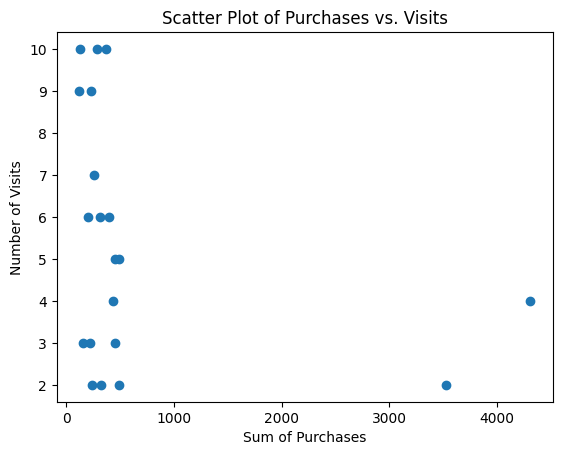

In [90]:
plt.scatter(sum_purchases, visits)
plt.title('Scatter Plot of Purchases vs. Visits')
plt.xlabel('Sum of Purchases')
plt.ylabel('Number of Visits');

**Завдання 7**. В попередньому завданні ми помітили, що викиди нам заважають отримати "правдиве" значення кореляції. Давайте вилучимо записи, які відповідають значенням з викидами в сумі покупок і обчисліть коеф. кореляції. Для цього поставте `threshold`, який дорінює середньому значенню + 2 стандартних вдіхилля суми покупок і всі значення, які більше за нього, будемо вважати викидами (є і інші правила для визначення викидів - з ним и познайомимось пізніше).

Вилучіть значення з обох масивів і обчисліть коеф. кореляції Пірсона з допомогою `numpy` для кількості візитів і суми покупок без записів-викидів. Виведіть результат на екран, побудуйте діаграму розсіювання і проаналізуйте результат: що можемо сказати про залежність в даних?

Поріг для викидів: 2917.04
Викиди: [4310 3524]
Кількість записів до: 20 після: 18
Коефіцієнт Пірсона без викидів: -0.37


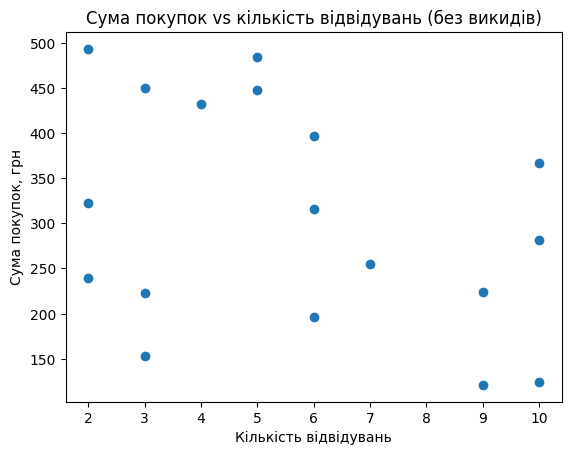

In [91]:
# перетворюємо списки на масиви, щоб зручно фільтрувати
purchases_array = np.array(sum_purchases)
visits_array = np.array(visits)

# поріг: середнє + 2 стандартних відхилення (ddof=1, бо це вибірка)
mean_purchases = np.mean(purchases_array)
std_purchases = np.std(purchases_array, ddof=1)
threshold = mean_purchases + 2 * std_purchases
print("Поріг для викидів:", threshold.round(2))

# маски: викиди більші за поріг, нормальні значення — решта
is_outlier = purchases_array > threshold
is_normal = purchases_array <= threshold
print("Викиди:", purchases_array[is_outlier])

# вилучаємо викиди з обох масивів, щоб пари не зламались
purchases_clean = purchases_array[is_normal]
visits_clean = visits_array[is_normal]
print("Кількість записів до:", len(purchases_array), "після:", len(purchases_clean))

pearson_clean = np.corrcoef(purchases_clean, visits_clean)[0, 1]
print("Коефіцієнт Пірсона без викидів:", pearson_clean.round(2))

plt.scatter(visits_clean, purchases_clean)
plt.xlabel("Кількість відвідувань")
plt.ylabel("Сума покупок, грн")
plt.title("Сума покупок vs кількість відвідувань (без викидів)")
plt.show()

# Без викидів r = -0.37: зв'язок досі слабкий і від'ємний, лише трохи сильніший, ніж з викидами.
# Точки на графіку розкидані, чіткої лінії немає.
# Тож кількість відвідувань майже не допомагає передбачити суму покупок.